In [27]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

plt.style.use("ggplot")

In [28]:
df = pd.read_csv("data 5.csv")

df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [29]:
print("Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDataset Information:")
df.info()

df.describe()

Shape: (569, 33)

Missing Values:
id                           0
diagnosis                    0
radius_mean                  0
texture_mean                 0
perimeter_mean               0
area_mean                    0
smoothness_mean              0
compactness_mean             0
concavity_mean               0
concave points_mean          0
symmetry_mean                0
fractal_dimension_mean       0
radius_se                    0
texture_se                   0
perimeter_se                 0
area_se                      0
smoothness_se                0
compactness_se               0
concavity_se                 0
concave points_se            0
symmetry_se                  0
fractal_dimension_se         0
radius_worst                 0
texture_worst                0
perimeter_worst              0
area_worst                   0
smoothness_worst             0
compactness_worst            0
concavity_worst              0
concave points_worst         0
symmetry_worst               0
fract

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [30]:
# Preprocessing
# Drop unnecessary ID and completely empty Unnamed columns if they exist
df = df.drop(columns=["id", "Unnamed: 32"], errors="ignore")

# Map diagnosis target to binary (M = 1, B = 0)
df['diagnosis'] = df['diagnosis'].map({'M': 1, 'B': 0})

# Features and Target
X = df.drop("diagnosis", axis=1)
y = df["diagnosis"]

# Handle missing values if any
imputer = SimpleImputer(strategy='mean')
X = imputer.fit_transform(X)

print("Shape after preprocessing:", X.shape)

Shape after preprocessing: (569, 30)


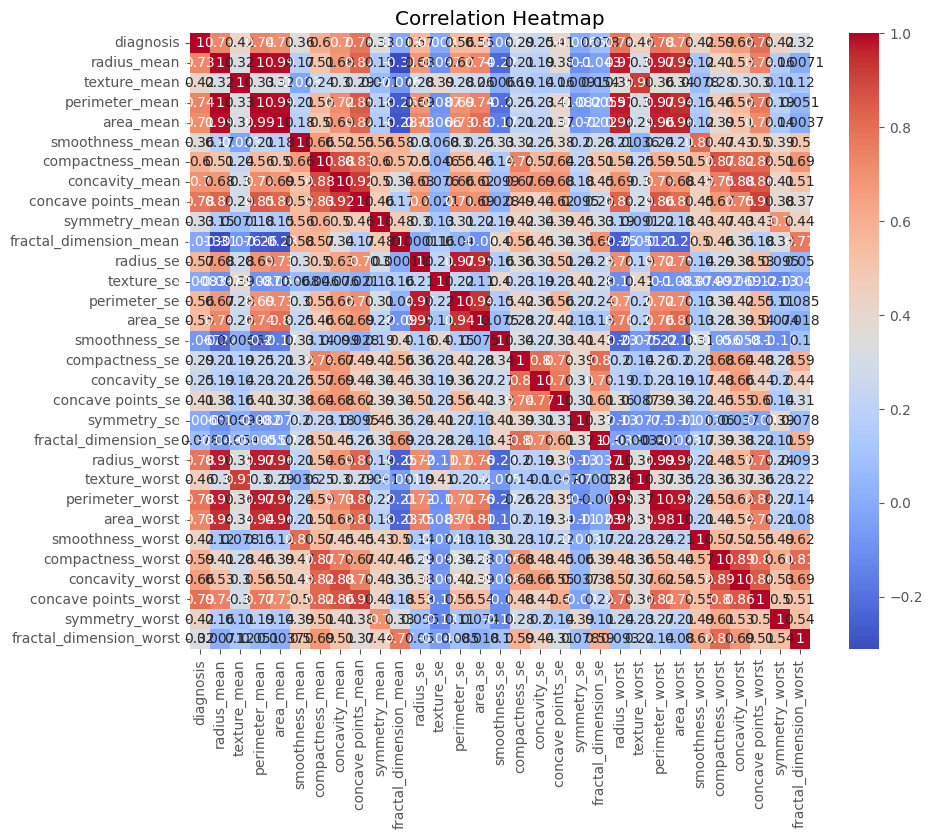

In [31]:
import seaborn as sns

plt.figure(figsize=(10,8))

sns.heatmap(
    df.corr(),
    cmap='coolwarm',
    annot=True
)

plt.title("Correlation Heatmap")
plt.show()

In [32]:
# Train-Test Split & Standardization
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 455
Testing samples: 114


In [33]:
# Train Ridge Model
ridge = LogisticRegression(
    penalty='l2',
    solver='liblinear',
    C=0.1,
    random_state=42
)

ridge.fit(X_train, y_train)

ridge_pred = ridge.predict(X_test)

ridge_accuracy = accuracy_score(y_test, ridge_pred)

print("Ridge Accuracy:", round(ridge_accuracy,4))

Ridge Accuracy: 0.9912


In [34]:
# Train Lasso Model
lasso = LogisticRegression(
    penalty='l1',
    solver='liblinear',
    C=0.05,
    random_state=42
)

lasso.fit(X_train, y_train)

lasso_pred = lasso.predict(X_test)

lasso_accuracy = accuracy_score(y_test, lasso_pred)

print("Lasso Accuracy:", round(lasso_accuracy,4))

Lasso Accuracy: 0.9649


In [35]:
# Compare accuracy
results = pd.DataFrame({

    "Model":["Ridge","Lasso"],

    "Accuracy":[ridge_accuracy,
                lasso_accuracy]

})

results

,Model,Accuracy
0,Ridge,0.991228
1,Lasso,0.964912


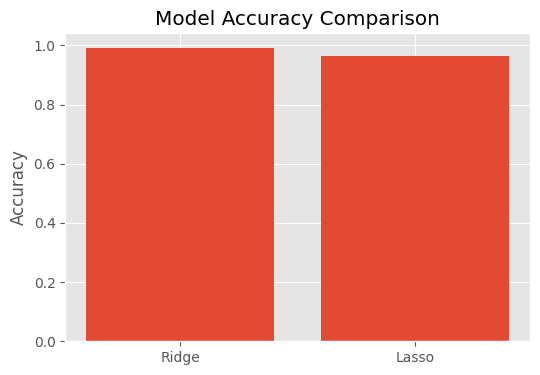

In [36]:
plt.figure(figsize=(6,4))

plt.bar(results["Model"],
        results["Accuracy"])

plt.title("Model Accuracy Comparison")

plt.ylabel("Accuracy")

plt.show()

In [37]:
print("Ridge Confusion Matrix")

print(confusion_matrix(y_test,ridge_pred))

print(classification_report(y_test,ridge_pred))

Ridge Confusion Matrix
[[71  0]
 [ 1 42]]
              precision    recall  f1-score   support

           0       0.99      1.00      0.99        71
           1       1.00      0.98      0.99        43

    accuracy                           0.99       114
   macro avg       0.99      0.99      0.99       114
weighted avg       0.99      0.99      0.99       114



In [38]:
print("Lasso Confusion Matrix")

print(confusion_matrix(y_test,lasso_pred))

print(classification_report(y_test,lasso_pred))

Lasso Confusion Matrix
[[69  2]
 [ 2 41]]
              precision    recall  f1-score   support

           0       0.97      0.97      0.97        71
           1       0.95      0.95      0.95        43

    accuracy                           0.96       114
   macro avg       0.96      0.96      0.96       114
weighted avg       0.96      0.96      0.96       114



In [39]:
# Coefficient Comparison
feature_names = df.drop("diagnosis", axis=1).columns

coef = pd.DataFrame({
    "Feature":feature_names,
    "Ridge":ridge.coef_[0],
    "Lasso":lasso.coef_[0]
})

coef.round(3)
coef

,Feature,Ridge,Lasso
0,radius_mean,0.357403,0.000000
1,texture_mean,0.398598,0.000000
2,perimeter_mean,0.347498,0.000000
3,area_mean,0.374550,0.000000
4,smoothness_mean,0.125217,0.000000
5,compactness_mean,-0.024754,0.000000
6,concavity_mean,0.378562,0.000000
7,concave points_mean,0.479329,0.868361
8,symmetry_mean,0.028115,0.000000
9,fractal_dimension_mean,-0.160351,0.000000


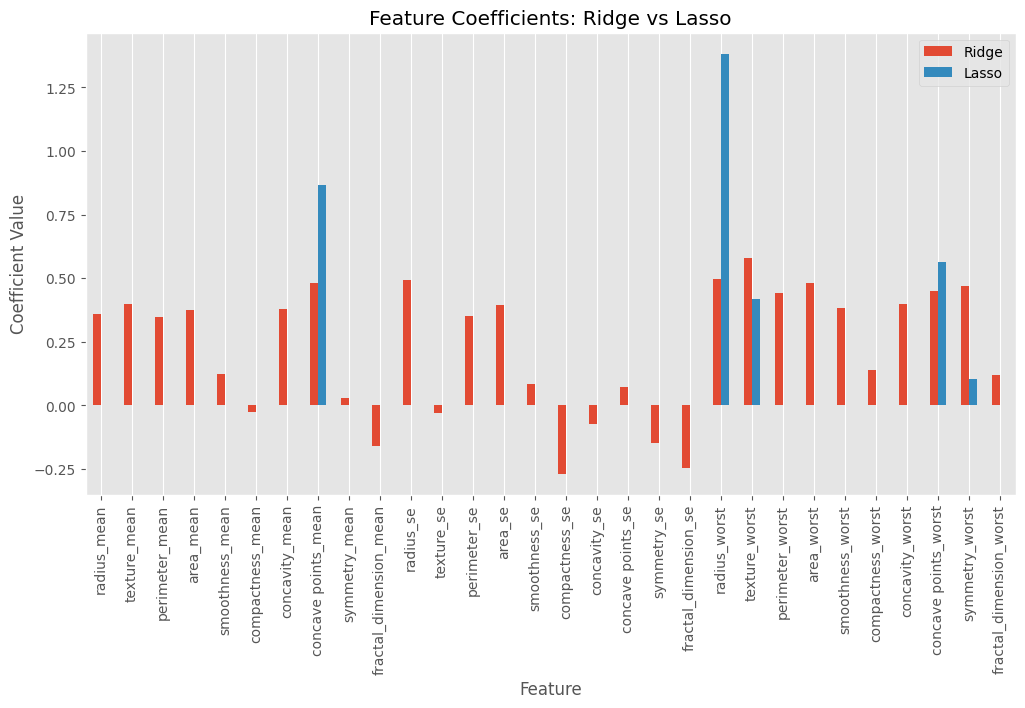

In [40]:
# Coefficient Bar Chart
coef.set_index("Feature").plot(
    kind="bar",
    figsize=(12,6)
)

plt.title("Feature Coefficients: Ridge vs Lasso")

plt.ylabel("Coefficient Value")

plt.grid(axis="y")

plt.show()

In [41]:
# Count Selected Features
ridge_features = np.sum(ridge.coef_[0] != 0)
lasso_features = np.sum(lasso.coef_[0] != 0)

print("Number of Features Used")

print("Ridge :", ridge_features)

print("Lasso :", lasso_features)

Number of Features Used
Ridge : 30
Lasso : 5
